# Integrated evaluator: visibility selection rules

Compare **performance-based**, **similarity-based**, and **dissimilarity-based** visibility selection using **three figures only**: (1) breakthrough discovery, (2) pairwise solution diversity, and (3) adopted solution quality.

All experiments keep **10 recommendations per recipient**, visibility extent **1.0**, and a visibility interval of **10 periods**. **Selection strength** varies from `0.0` (10 randomly selected entries) to `1.0` (all 10 entries prioritized by the rule); intermediate settings prioritize 2, 4, 6, or 8 entries and fill the remaining slots randomly. Similarity and dissimilarity are assessed relative to each recipient's current solution. A selection strength of `0.0` is **random selection, not search-apart**.

All outcomes concern the recipient crowd. Curves represent the **unweighted mean across `K = 9, ..., 17`**, as in the three original evaluators. **Lower breakthrough rank is better**; adoption quality is the true NK fitness of adopted solutions (undefined when no solution was adopted).

In [1]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np

# Use the same visual conventions as the three source evaluators.
legend_properties = {'weight': 'bold', 'size': 11}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_green = '#28A9A1'


def format_axis(ax):
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.4)
    ax.tick_params(axis='both', labelsize=11)
    ax.set_axisbelow(True)
    return ax


def safe_nanmean(values, axis=None):
    # Retain NaN when adoption quality is undefined for all K values.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)

## 1. Configuration

These three folders and pickle prefixes come from the uploaded evaluators. Change `base_folder` if the results have moved. Figures are saved together in `Integrated_selection_figures` under the common experiment directory.

In [2]:
# Common simulation settings (matching all three uploaded notebooks).
N = 18
K_list = list(range(9, N))  # K = 9, ..., 17
agent_num = 100
visibility_extent = 1.0
recommendation_num = 10
visibility_interval = 10
selection_strength_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
x = np.asarray(selection_strength_list, dtype=float)

# Parent of Rank_based / Similarity_based / Dissimilarity_based result folders.
base_folder = Path('/Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num')

# Matching the existing simulation-output naming conventions exactly.
selection_rules = {
    'Performance-based': {
        'folder': base_folder / 'Rank_based',
        'prefix': 'visibility_rank_selection_strength',
        'color': nus_blue,
        'marker': 'o',
        'linestyle': '-',
    },
    'Similarity-based': {
        'folder': base_folder / 'Similarity_based',
        'prefix': 'visibility_similarity_selection_strength',
        'color': morandi_green,
        'marker': 's',
        'linestyle': '--',
    },
    'Dissimilarity-based': {
        'folder': base_folder / 'Dissimilarity_based',
        'prefix': 'visibility_novelty_selection_strength',
        'color': nus_orange,
        'marker': '^',
        'linestyle': '-.',
    },
}

# Plot only the three requested outcomes.
outcomes = {
    'breakthrough_rank': {
        'ylabel': 'Best solution rank (lower is better)',
        'title': 'Breakthrough discovery across selection strength',
        'filename': 'Breakthrough_rank_across_selection_strength.png',
    },
    'pairwise_diversity': {
        'ylabel': 'Pairwise solution diversity',
        'title': 'Pairwise diversity across selection strength',
        'filename': 'Pairwise_diversity_across_selection_strength.png',
    },
    'adopted_solution_fitness': {
        'ylabel': 'Adopted solution fitness',
        'title': 'Adopted solution quality across selection strength',
        'filename': 'Adopted_solution_quality_across_selection_strength.png',
    },
}

save_figures = True
figure_folder = base_folder / 'Integrated_selection_figures'

print('Selection strengths:', selection_strength_list)
print('Fixed number of recommendations:', recommendation_num)
for rule, settings in selection_rules.items():
    print(f'{rule:20s}: {settings["folder"]}')

Selection strengths: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
Fixed number of recommendations: 10
Performance-based   : /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num/Rank_based
Similarity-based    : /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num/Similarity_based
Dissimilarity-based : /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num/Dissimilarity_based


## 2. Load and validate the three outcomes

Each file contains nine pre-averaged values, one per landscape complexity `K`. The evaluator loads the same three outcome families for all three rules; it **does not** assume that random-selection replications at `strength = 0.0` produced identical values across independently simulated experiments. Missing or malformed files raise an informative error rather than being plotted as zeros.

In [3]:
def result_file(settings, strength, dv):
    name = (
        f'{settings["prefix"]}_{strength}'
        f'_recommendation_num_{recommendation_num}_interval_{visibility_interval}'
        f'_{dv}_across_K_size_{agent_num}'
    )
    return settings['folder'] / name


def load_selection_results():
    results = {}
    problems = []
    for rule, settings in selection_rules.items():
        results[rule] = {}
        for dv in outcomes:
            values_across_strengths = []
            for strength in selection_strength_list:
                filepath = result_file(settings, strength, dv)
                if not filepath.is_file():
                    problems.append(f'Missing: {filepath}')
                    continue
                try:
                    with open(filepath, 'rb') as infile:
                        values = np.asarray(pickle.load(infile), dtype=float)
                except (OSError, EOFError, pickle.UnpicklingError, TypeError, ValueError) as exc:
                    problems.append(f'Invalid: {filepath} ({exc})')
                    continue
                if values.shape != (len(K_list),):
                    problems.append(
                        f'Wrong shape: {filepath} (got {values.shape}; expected {(len(K_list),)})'
                    )
                    continue
                values_across_strengths.append(values)
            if len(values_across_strengths) == len(selection_strength_list):
                results[rule][dv] = np.stack(values_across_strengths)  # (strength, K)

    if problems:
        preview = '\n'.join(problems[:12])
        extra = f'\n... and {len(problems) - 12} more' if len(problems) > 12 else ''
        raise FileNotFoundError(
            f'{len(problems)} missing or invalid pickle file(s). '
            'Check base_folder, recommendation_num, visibility_interval, and agent_num.\n'
            + preview + extra
        )
    return results


data = load_selection_results()
for rule in selection_rules:
    print(f'{rule}: ' + ', '.join(f'{dv}: {data[rule][dv].shape}' for dv in outcomes))

# Basic integrity checks, without modifying the source data.
for rule in selection_rules:
    for dv in outcomes:
        values = data[rule][dv]
        finite = values[np.isfinite(values)]
        if not finite.size:
            raise ValueError(f'No valid {dv} observations for {rule}.')
        if dv == 'breakthrough_rank':
            minimum, maximum = 1, 2 ** N
        else:
            minimum, maximum = 0, 1
        if np.any((finite < minimum - 1e-8) | (finite > maximum + 1e-8)):
            warnings.warn(f'{rule}: {dv} contains values outside [{minimum}, {maximum}].')

# Unweighted means over all nine K values; preserve NaN adoption quality.
means = {
    rule: {dv: safe_nanmean(data[rule][dv], axis=1) for dv in outcomes}
    for rule in selection_rules
}

if save_figures:
    figure_folder.mkdir(parents=True, exist_ok=True)
    print('Figures will be saved in:', figure_folder)

Performance-based: breakthrough_rank: (6, 9), pairwise_diversity: (6, 9), adopted_solution_fitness: (6, 9)
Similarity-based: breakthrough_rank: (6, 9), pairwise_diversity: (6, 9), adopted_solution_fitness: (6, 9)
Dissimilarity-based: breakthrough_rank: (6, 9), pairwise_diversity: (6, 9), adopted_solution_fitness: (6, 9)
Figures will be saved in: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num/Integrated_selection_figures


## 3. Three integrated figures

Every figure has **exactly three lines**, one per selection rule. The horizontal axis is the same for all figures; differences in line patterns and markers make the rules distinguishable in grayscale.

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num/Integrated_selection_figures/Breakthrough_rank_across_selection_strength.png


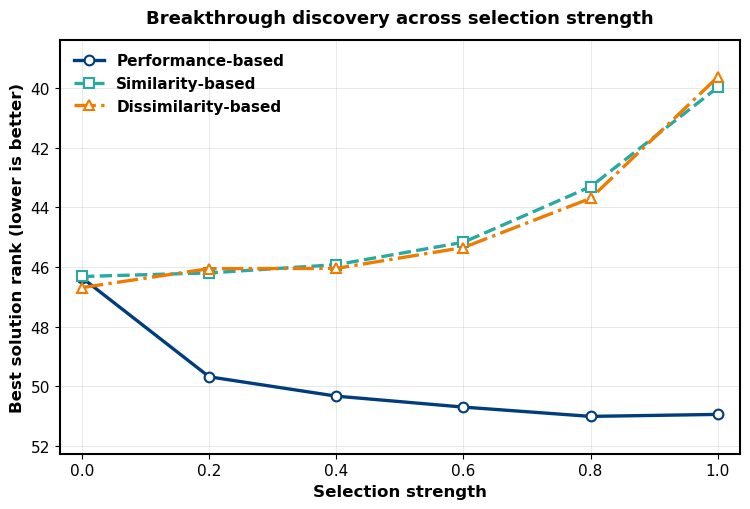

In [4]:
def plot_comparison(dv):
    fig, ax = plt.subplots(figsize=(7.6, 5.2))
    format_axis(ax)

    for rule, settings in selection_rules.items():
        y = means[rule][dv]
        ax.plot(
            x, y, label=rule, linewidth=2.4, markersize=7,
            marker=settings['marker'], linestyle=settings['linestyle'],
            color=settings['color'], markerfacecolor='white',
            markeredgewidth=1.5,
        )

    ax.set_xticks(x)
    ax.set_xlim(-0.035, 1.035)
    ax.margins(y=0.11)
    ax.set_xlabel('Selection strength', fontweight='bold', fontsize=12)
    ax.set_ylabel(outcomes[dv]['ylabel'], fontweight='bold', fontsize=12)
    ax.set_title(outcomes[dv]['title'], fontweight='bold', fontsize=13, pad=12)
    ax.legend(frameon=False, prop=legend_properties, loc='best')

    if dv == 'breakthrough_rank':
        ax.invert_yaxis()  # Rank 1 is best; upward means better breakthrough discovery.

    fig.tight_layout()
    if save_figures:
        output = figure_folder / outcomes[dv]['filename']
        fig.savefig(output, dpi=300, bbox_inches='tight', transparent=True)
        print('Saved:', output)
    plt.show()

# Figure 1. Breakthrough discovery (best solution rank).
plot_comparison('breakthrough_rank')

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num/Integrated_selection_figures/Pairwise_diversity_across_selection_strength.png


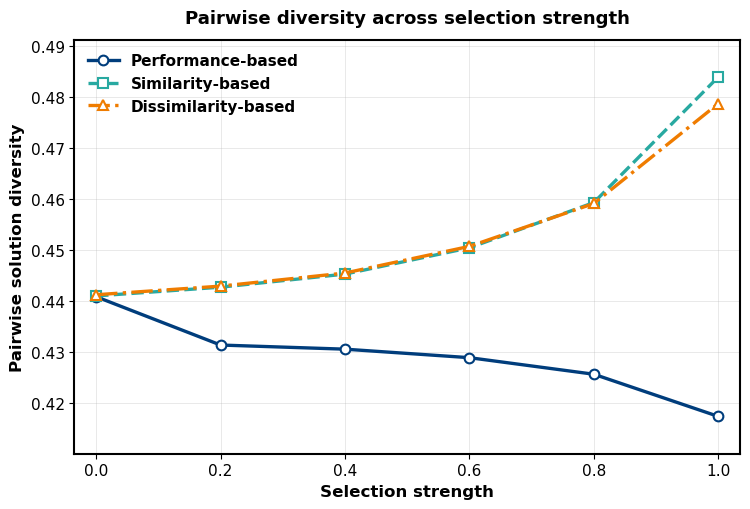

In [5]:
# Figure 2. Dispersion (normalized pairwise Hamming distance).
plot_comparison('pairwise_diversity')

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num/Integrated_selection_figures/Adopted_solution_quality_across_selection_strength.png


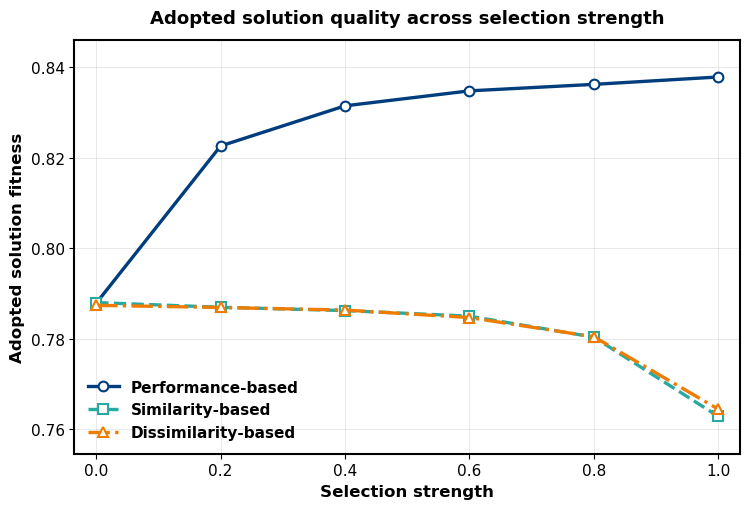

In [6]:
# Figure 3. Orientation (mean true fitness of adopted solutions).
plot_comparison('adopted_solution_fitness')